# 08 – Final Test Against the Bookmakers

**Objective:** measure the final model on matches it has never seen, and find out whether it could beat bookmakers' odds.

**Key results**
- **Honest score:** 66.98% accuracy and a log loss of 0.5929 on 12,215 unseen matches, against 68.38% and 0.5849 on validation.
- **Beats simple methods:** Elo alone scores 65.87%, and the ATP ranking alone scores 63.81%.
- **Doesn't beat the bookmakers:** on the same 10,375 matches, Pinnacle scores 67.71% and 0.5889, and our model scores 66.57% and 0.5959.
- **Not profitable:** the main betting rule returns −1.22%, with a 95% interval from −5.28% to +3.08%.

## 1. Rules fixed before looking at any result

Writing the rules down first stops us from choosing, after the fact, whichever version happens to look profitable.

| Choice | Decision |
|---|---|
| **Model** | The logistic regression from notebook 07, with 60 columns and nothing changed |
| **Test matches** | Main tour, 2022 to June 2026, without Davis Cup or walkovers |
| **Training** | Walk-forward: each year is predicted by a model trained on 2005 up to the year before |
| **Main bookmaker** | Pinnacle, 2022–2025. It is widely seen as the sharpest bookmaker, but its odds are nearly absent from the 2026 file |
| **Second bookmaker** | Bet365, 2022–2026 |
| **Betting rule** | Bet 1 unit on a player when model probability × odds − 1 is at least 5% |
| **Retirements** | Bets are refunded, as a simplification. Rules differ between bookmakers, so section 6 also tests the alternative |
| **Is it profitable?** | Only if the 95% confidence interval of the return is entirely above zero |

Any other threshold or bookmaker shown below is **exploratory** and can't be used to claim a profit.

**About the odds:** the source says they "generally represent the most recent before play starts". These are close to closing odds, the hardest odds to beat, because the market has already absorbed nearly all the news.

In [1]:
import sqlite3
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.api as sm

sys.path.insert(0, "../src")
from tennis_domain_features import DOMAIN_GROUPS
from tennis_elo import win_probability
from tennis_features import FEATURE_GROUPS
from tennis_models import INTERACTIONS, add_interactions, logistic_model, score, walk_forward
from tennis_odds import link_odds, load_odds

CHART_COLOR = "#2a78d6"
TEXT_COLOR = "#52514e"
GRID_COLOR = "#e4e3df"
REFERENCE_COLOR = "#8a8981"
TEST_YEARS = range(2022, 2027)

conn = sqlite3.connect(Path("../data/processed/tennis.db"))
data = pd.read_sql_query("SELECT * FROM final_features WHERE tourney_level <> 'D'", conn)
data = add_interactions(data)
test = data["year"].isin(TEST_YEARS)

ORDER = ["Elo", "Ranking", "Serve and return", "Form", "Fatigue and fitness", "Experience",
         "Style and age", "Head to head", "Draw", "Home"]
FINAL_COLUMNS = (
    [c for group in ORDER for c in FEATURE_GROUPS[group]]
    + list(INTERACTIONS) + DOMAIN_GROUPS["Tournament history"]
)
print(f"{test.sum():,} test matches, {len(FINAL_COLUMNS)} model columns")

12,215 test matches, 60 model columns


## 2. The honest score

This is the first time these matches are scored. The validation score from notebook 07 is in the first row, for comparison.

In [2]:
model_p = walk_forward(data, FINAL_COLUMNS, logistic_model, years=TEST_YEARS)
rank_p = walk_forward(data, ["d_log_rank"], logistic_model, years=TEST_YEARS)

overall = pd.DataFrame([
    {"model": "Final model on validation, 2015–2021 (notebook 07)", "accuracy_pct": 68.38, "log_loss": 0.5849},
    {"model": "Final model on test", **score(model_p[test])},
    {"model": "Elo only on test", **score(win_probability(data.loc[test, "d_elo_combined"], 0))},
    {"model": "ATP ranking only on test", **score(rank_p[test])},
])
overall

,model,accuracy_pct,log_loss
0,"Final model on validation, 2015–2021 (notebook...",68.38,0.5849
1,Final model on test,66.98,0.5929
2,Elo only on test,65.87,0.6083
3,ATP ranking only on test,63.81,0.6310


In [3]:
pd.DataFrame(
    [{"year": year, "n_matches": int((data["year"] == year).sum()), **score(model_p[data["year"] == year])}
     for year in TEST_YEARS]
)

,year,n_matches,accuracy_pct,log_loss
0,2022,2692,67.98,0.5851
1,2023,2747,65.56,0.5979
2,2024,2878,66.40,0.5869
3,2025,2588,67.35,0.6041
4,2026,1310,68.47,0.5890


## 3. Linking the odds

Our data and the odds files have no shared ID, and they write names differently ("Carlos Alcaraz" and "Alcaraz C."). Matches are linked using both players' names, the date and the round.

In [4]:
names = pd.read_sql_query("""
SELECT m.tourney_id, m.match_num, m.round, t.tourney_name, t.tourney_date,
       w.name_first AS winner_first, w.name_last AS winner_surname,
       l.name_first AS loser_first, l.name_last AS loser_surname
FROM matches AS m
JOIN tournaments AS t ON m.tourney_id = t.tourney_id
JOIN players AS w ON m.winner_id = w.player_id
JOIN players AS l ON m.loser_id = l.player_id
""", conn)

test_matches = data.loc[test, ["tourney_id", "match_num", "year", "tourney_level", "d_elo_combined"]].copy()
test_matches["model_p"] = model_p[test]
test_matches = test_matches.merge(names, on=["tourney_id", "match_num"], validate="one_to_one")
test_matches["start_date"] = pd.to_datetime(test_matches["tourney_date"])

odds = load_odds("../data/raw/odds", first_year=2022)
test_matches["odds_row"] = link_odds(test_matches, odds)
linked = test_matches.dropna(subset=["odds_row"]).join(odds, on="odds_row")

print(f"Linked {len(linked):,} of {len(test_matches):,} test matches ({len(linked) / len(test_matches):.1%})")
test_matches.assign(linked=test_matches["odds_row"].notna()).groupby("tourney_level")["linked"].agg(["size", "mean"]).round(3)

Linked 11,790 of 12,215 test matches (96.5%)


,size,mean
tourney_level,,
A,6694,0.958
F,90,0.489
G,2271,0.995
M,3097,0.993
O,63,0.000


## 4. Model against the market

A bookmaker's odds contain a **margin**, so the two implied probabilities add up to more than 100%. Dividing each by their total removes it. Odds of 1.50 and 2.60 imply 66.7% and 38.5%, which add up to 105.1%, and they become 63.4% and 36.6%.

Each comparison uses only matches where that bookmaker's odds exist.

In [5]:
def implied(odds_winner, odds_loser):
    """Winner's probability from the odds, with the bookmaker's margin removed."""
    return (1 / odds_winner) / (1 / odds_winner + 1 / odds_loser)


def compare(label, winner_col, loser_col, mask):
    rows = linked[mask & linked[winner_col].notna() & linked[loser_col].notna()]
    margin = (1 / rows[winner_col] + 1 / rows[loser_col] - 1).mean()
    return [
        {"bookmaker": label, "who": "Bookmaker", "n_matches": len(rows), "avg_margin_pct": round(100 * margin, 2),
         **score(implied(rows[winner_col], rows[loser_col]))},
        {"bookmaker": label, "who": "Our model", "n_matches": len(rows), "avg_margin_pct": np.nan,
         **score(rows["model_p"])},
    ]


through_2025 = linked["year"] <= 2025
everything = pd.Series(True, index=linked.index)
pd.DataFrame(
    compare("Pinnacle 2022–2025", "PSW", "PSL", through_2025)
    + compare("Bet365 2022–2026", "B365W", "B365L", everything)
    + compare("Market average 2022–2026", "AvgW", "AvgL", everything)
)

,bookmaker,who,n_matches,avg_margin_pct,accuracy_pct,log_loss
0,Pinnacle 2022–2025,Bookmaker,10375,2.62,67.71,0.5889
1,Pinnacle 2022–2025,Our model,10375,NaN,66.57,0.5959
2,Bet365 2022–2026,Bookmaker,11743,5.23,67.88,0.5885
3,Bet365 2022–2026,Our model,11743,NaN,66.87,0.5946
4,Market average 2022–2026,Bookmaker,11777,5.58,68.02,0.5879
5,Market average 2022–2026,Our model,11777,NaN,66.88,0.5941


### Does the model know anything the market doesn't?

This regression predicts results from both the market's and the model's opinions together. If the model's coefficient is about 0, it adds nothing beyond the odds. Each match is randomly shown from one player's side, because a regression needs both outcomes.

In [6]:
rows = linked.dropna(subset=["PSW", "PSL"])
rows = rows[rows["year"] <= 2025]
logit = lambda p: np.log(p / (1 - p))
sign = np.random.default_rng(0).choice([1, -1], size=len(rows))

X = pd.DataFrame({
    "market": sign * logit(implied(rows["PSW"], rows["PSL"])),
    "our_model": sign * logit(rows["model_p"]),
})
y = (sign == 1).astype(int)
fit = sm.Logit(y, X).fit(disp=0)
fit.summary2().tables[1][["Coef.", "Std.Err.", "[0.025", "0.975]"]].round(3)

,Coef.,Std.Err.,[0.025,0.975]
market,0.910,0.076,0.762,1.059
our_model,0.128,0.073,-0.014,0.271


**Finding:** the market's coefficient is close to 1, so its odds carry nearly all the information. Our model's coefficient is 0.128, and its 95% interval (−0.014 to 0.271) includes zero. At most this is a weak hint that the model adds something, not evidence.

## 5. Is the model calibrated on new matches?

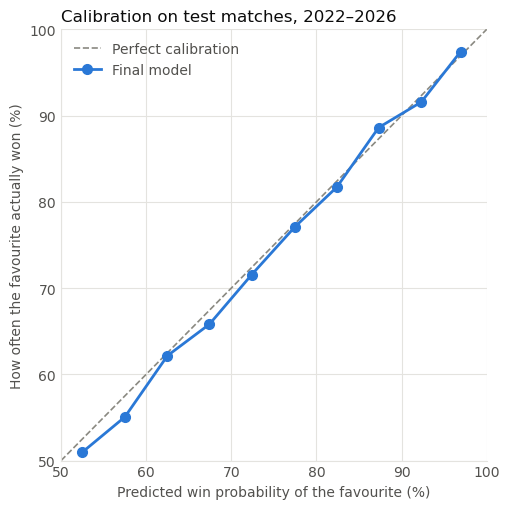

,n_matches,predicted,actual
0,1949,0.525,0.509
1,1969,0.575,0.551
2,1792,0.625,0.622
3,1594,0.674,0.658
4,1406,0.724,0.716
5,1231,0.775,0.771
6,902,0.824,0.817
7,676,0.873,0.886
8,463,0.923,0.916
9,233,0.969,0.974


In [7]:
p = model_p[test]
favourite = np.maximum(p, 1 - p)
table = pd.DataFrame({"predicted": favourite, "won": p > 0.5})
table["bucket"] = pd.cut(table["predicted"], np.arange(0.5, 1.01, 0.05), include_lowest=True)
calibration = (
    table.groupby("bucket", observed=True)
    .agg(n_matches=("won", "size"), predicted=("predicted", "mean"), actual=("won", "mean"))
    .reset_index(drop=True)
)

fig, ax = plt.subplots(figsize=(5.2, 5.2))
ax.plot([50, 100], [50, 100], color=REFERENCE_COLOR, linestyle="--", linewidth=1.2, label="Perfect calibration")
ax.plot(100 * calibration["predicted"], 100 * calibration["actual"], color=CHART_COLOR,
        linewidth=2, marker="o", markersize=7, label="Final model")
ax.set_xlim(50, 100)
ax.set_ylim(50, 100)
ax.set_xlabel("Predicted win probability of the favourite (%)", color=TEXT_COLOR)
ax.set_ylabel("How often the favourite actually won (%)", color=TEXT_COLOR)
ax.set_title("Calibration on test matches, 2022–2026", loc="left", fontsize=12, color="#0b0b0b")
ax.spines[["top", "right"]].set_visible(False)
ax.spines[["left", "bottom"]].set_color(GRID_COLOR)
ax.grid(color=GRID_COLOR, linewidth=0.8)
ax.set_axisbelow(True)
ax.tick_params(colors=TEXT_COLOR, length=0)
ax.legend(frameon=False, labelcolor=TEXT_COLOR, loc="upper left")
plt.tight_layout()
plt.show()

calibration.round(3)

## 6. Betting simulation

**Value bet:** bet when model probability × odds − 1 reaches the threshold. For example, a probability of 48% at odds of 2.50 gives 0.48 × 2.50 − 1 = 20%.

**Return on investment (ROI):** total profit divided by total staked. **Bootstrap:** the bets are resampled 10,000 times to see how much the ROI could vary by luck alone.

In [8]:
def simulate(frame, winner_col, loser_col, threshold=0.05, refund_retirements=True):
    """One row per bet, with a flat stake of 1 unit."""
    rows = frame.dropna(subset=[winner_col, loser_col]).copy()
    edge_winner = rows["model_p"] * rows[winner_col] - 1
    edge_loser = (1 - rows["model_p"]) * rows[loser_col] - 1

    on_winner = (edge_winner >= threshold) & (edge_winner >= edge_loser)
    on_loser = (edge_loser >= threshold) & (edge_loser > edge_winner)

    rows = rows[on_winner | on_loser].copy()
    won = on_winner[rows.index]
    rows["bet_odds"] = np.where(won, rows[winner_col], rows[loser_col])
    rows["profit"] = np.where(won, rows[winner_col] - 1, -1.0)
    rows["staked"] = 1.0
    if refund_retirements:
        void = rows["Comment"].isin(["Retired", "Awarded"])
        rows.loc[void, ["profit", "staked"]] = 0.0
    return rows


def summarise(bets, label):
    active = bets[bets["staked"] > 0]
    generator = np.random.default_rng(0)
    samples = generator.integers(0, len(active), size=(10_000, len(active)))
    roi_samples = active["profit"].to_numpy()[samples].mean(axis=1)
    return {
        "strategy": label, "n_bets": len(active), "avg_odds": round(active["bet_odds"].mean(), 2),
        "bets_won_pct": round(100 * (active["profit"] > 0).mean(), 1),
        "profit_units": round(active["profit"].sum(), 1), "roi_pct": round(100 * active["profit"].mean(), 2),
        "roi_low_95": round(100 * np.percentile(roi_samples, 2.5), 2),
        "roi_high_95": round(100 * np.percentile(roi_samples, 97.5), 2),
    }


pinnacle = linked[linked["year"] <= 2025]
main_bets = simulate(pinnacle, "PSW", "PSL")
pd.DataFrame([summarise(main_bets, "Main rule: Pinnacle, edge of 5% or more")])

,strategy,n_bets,avg_odds,bets_won_pct,profit_units,roi_pct,roi_low_95,roi_high_95
0,"Main rule: Pinnacle, edge of 5% or more",5271,3.39,41.2,-64.3,-1.22,-5.28,3.08


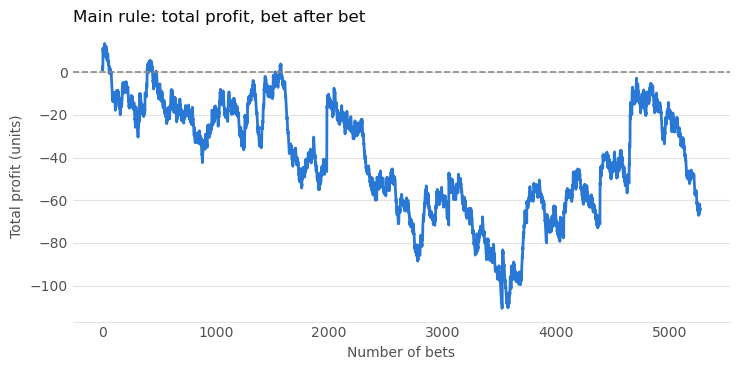

Largest fall from a peak: 124.0 units


,strategy,n_bets,avg_odds,bets_won_pct,profit_units,roi_pct,roi_low_95,roi_high_95
0,2022,1425,3.29,40.1,-13.0,-0.91,-8.21,6.62
1,2023,1309,3.41,40.6,-61.6,-4.70,-12.86,4.06
2,2024,1339,3.44,42.1,12.7,0.95,-7.82,10.16
3,2025,1198,3.44,42.2,-2.4,-0.20,-8.74,8.89


In [9]:
ordered = main_bets[main_bets["staked"] > 0].sort_values(["Date", "match_num"]).reset_index(drop=True)
cumulative = ordered["profit"].cumsum()

fig, ax = plt.subplots(figsize=(7.5, 3.8))
ax.plot(cumulative.index + 1, cumulative, color=CHART_COLOR, linewidth=2)
ax.axhline(0, color=REFERENCE_COLOR, linewidth=1.2, linestyle="--")
ax.set_xlabel("Number of bets", color=TEXT_COLOR)
ax.set_ylabel("Total profit (units)", color=TEXT_COLOR)
ax.set_title("Main rule: total profit, bet after bet", loc="left", fontsize=12, color="#0b0b0b")
ax.spines[["top", "right", "left"]].set_visible(False)
ax.spines["bottom"].set_color(GRID_COLOR)
ax.grid(axis="y", color=GRID_COLOR, linewidth=0.8)
ax.set_axisbelow(True)
ax.tick_params(colors=TEXT_COLOR, length=0)
plt.tight_layout()
plt.show()

print(f"Largest fall from a peak: {(cumulative.cummax() - cumulative).max():.1f} units")
pd.DataFrame([summarise(main_bets[main_bets["year"] == year], str(year)) for year in range(2022, 2026)])

### Exploratory checks

**These can't be used to claim a profit.** With many variations, one is likely to look good just by chance. They only show how sensitive the result is.

In [10]:
rows = [summarise(simulate(pinnacle, "PSW", "PSL", threshold=t), f"Pinnacle, edge of {t:.0%} or more") for t in [0.0, 0.02, 0.10, 0.15]]
rows.append(summarise(simulate(pinnacle, "PSW", "PSL", refund_retirements=False), "Pinnacle, 5%, retirements settled"))
rows.append(summarise(simulate(linked, "B365W", "B365L"), "Bet365, 5%, 2022–2026"))
rows.append(summarise(simulate(linked, "AvgW", "AvgL"), "Market average, 5%, 2022–2026"))
rows.append(summarise(simulate(linked, "MaxW", "MaxL"), "Best odds across bookmakers, 5%, 2022–2026"))
pd.DataFrame(rows)

,strategy,n_bets,avg_odds,bets_won_pct,profit_units,roi_pct,roi_low_95,roi_high_95
0,"Pinnacle, edge of 0% or more",8210,2.95,46.6,-202.6,-2.47,-5.42,0.61
1,"Pinnacle, edge of 2% or more",6906,3.12,44.3,-133.8,-1.94,-5.37,1.61
2,"Pinnacle, edge of 10% or more",3472,3.85,36.7,-44.2,-1.27,-6.79,4.48
3,"Pinnacle, edge of 15% or more",2240,4.38,33.0,18.9,0.84,-6.72,9.23
4,"Pinnacle, 5%, retirements settled",5415,3.40,41.2,-58.5,-1.08,-5.13,3.16
5,"Bet365, 5%, 2022–2026",4533,3.09,40.4,-203.7,-4.49,-8.38,-0.44
6,"Market average, 5%, 2022–2026",4188,2.90,41.0,-218.9,-5.23,-9.25,-1.17
7,"Best odds across bookmakers, 5%, 2022–2026",7162,3.52,41.9,79.9,1.12,-2.45,4.84


In [11]:
bets = main_bets[main_bets["staked"] > 0].copy()
bets["bet_type"] = np.where(bets["bet_odds"] < 2, "On the favourite (odds under 2)", "On the underdog (odds of 2 or more)")
pd.DataFrame([summarise(group, label) for label, group in bets.groupby("bet_type")])

,strategy,n_bets,avg_odds,bets_won_pct,profit_units,roi_pct,roi_low_95,roi_high_95
0,On the favourite (odds under 2),1628,1.60,62.7,-26.1,-1.61,-5.37,2.11
1,On the underdog (odds of 2 or more),3643,4.19,31.6,-38.2,-1.05,-6.77,4.90


## 7. Conclusions

| Question | Answer |
|---|---|
| Does the model work on new matches? | Yes: 66.98% accuracy, above Elo and the ATP ranking, with good calibration |
| Is it better than bookmakers? | No: Pinnacle's accuracy and log loss are both better |
| Would the main betting rule have made money? | No: the return was −1.22%, and the interval includes both losses and gains |
| Is there any proven edge? | No. The rule passes its pre-set test only if the whole interval is above zero |

**Why the score fell from validation to test:** the settings were chosen on the validation years, which made that score slightly optimistic. Different years can also be harder to predict. Elo alone fell too, from 67.56% to 65.87%.

**The most positive reading:** the rule's loss is smaller than Pinnacle's average margin of 2.62%, so the model isn't simply betting at random. This isn't proof of skill, because the interval is wide.

**Limits**
- **Best odds across bookmakers show +1.12%,** but this is exploratory, its interval includes zero, and taking the best price on every bet isn't realistic.
- **Betting limits and timing aren't modelled.** Winning accounts get limited, and odds can move before a bet is placed.
- **Half the matches trigger a bet.** A real edge should be rarer, so most of the model's disagreements with the market are probably noise.
- **Matches missing odds:** 3.5% of test matches couldn't be linked, mainly team events and the Olympics.

**Conclusion:** the model is a sound forecasting tool, but this test gives no reason to bet real money with it.